
# Wildfires as a Critical Phenomenon

Real wildfire sizes don't cluster around a typical value the way, say,
adult heights do. Instead the number of fires that burn *s* acres falls
off as a **power law**, $N(s) \sim s^{-\alpha}$: no characteristic scale,
just fewer and fewer fires as size grows, all the way from a scorched
patch to a regional disaster. That scale-free signature is the calling
card of **self-organized criticality (SOC)** — a system that tunes
*itself* to the edge of a phase transition, with no dial anyone has to
turn.

This notebook builds the classic toy model of that idea, the
**Drossel-Schwabl forest-fire model**, from four local rules, and shows
both hallmarks of SOC coming out of the simulation:

1. **Power-law distributed event sizes** — fire sizes span decades with
   no typical scale, and a power law fits the tail far better than an
   exponential.
2. **1/f-type ("pink/colored") noise** — the time series of "how much is
   burning right now" has power at every time scale, with no
   characteristic frequency — the temporal fingerprint of the same
   criticality.

This is the first of a planned series of small, self-contained SOC demos
in this repository (`toySystems/`); shared fitting and plotting code lives
in `../../common/` so later demos (sandpiles, Ising avalanches, ...) reuse
the same statistical machinery and visual language.


In [1]:

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent.parent))  # -> toySystems/

import numpy as np
from IPython.display import Video, Image, display

from common import powerlaw, spectral
from common.viz import set_style, save_fig, show_grid, PALETTE, ACCENT, ACCENT2, MUTED
from wildfire.model import ForestFireModel
from wildfire.viz import animate_grid

import matplotlib.pyplot as plt

set_style()

FIG_DIR = Path("../figures")
VID_DIR = Path("../videos")
DATA_DIR = Path("../data")
for d in (FIG_DIR, VID_DIR, DATA_DIR):
    d.mkdir(exist_ok=True, parents=True)

RNG_SEED = 20260910



## The model

The lattice is an $L \times L$ grid on a torus (periodic boundaries, so no
edge cuts a fire short). Every site is `empty`, `tree`, or `burning`.
Every tick, **every site updates at once**:

| current state | becomes... |
|---|---|
| burning | empty (ash) |
| tree, with a burning neighbor | burning (the fire spreads) |
| tree, no burning neighbor | burning, with small probability $f$ (lightning) |
| empty | tree, with probability $p$ (growth) |

The only requirement for criticality is a **separation of time scales**,
$f \ll p$: fire must spread much faster than the forest regrows. Given
that, the forest density is *not* a parameter you choose — it's an output.
The system spends most of its time slowly regrowing, gets struck,
and the resulting cascade trims it back down, self-tuning to hover just
below the site-percolation threshold ($\approx 0.593$ for a square
lattice) indefinitely, without anyone fine-tuning a control parameter to
a critical point. That's the "self-organized" in self-organized
criticality — see `wildfire/model.py` for the ~20-line implementation.


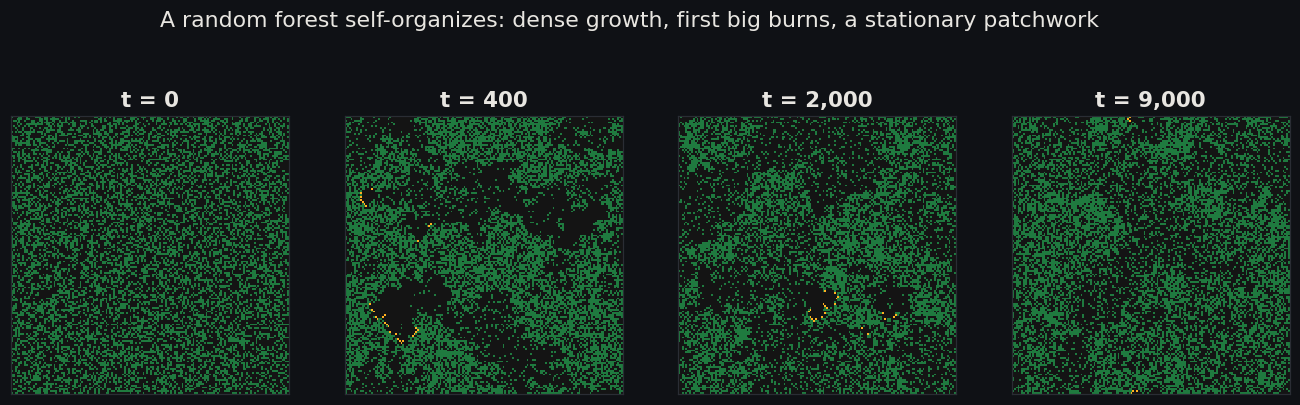

In [2]:

model = ForestFireModel(L=150, p=1e-3, f=1e-5, initial_density=0.4, seed=RNG_SEED)

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
checkpoints = [0, 400, 2000, 9000]
shown = 0
step_target = 0
snaps = {}
for target in checkpoints:
    while model.t < target:
        model.step()
    snaps[target] = model.grid.copy()

for ax, t in zip(axes, checkpoints):
    show_grid(ax, snaps[t], title=f"t = {t:,}")

fig.suptitle("A random forest self-organizes: dense growth, first big burns, a stationary patchwork",
             y=1.05, color="#e8e6e1")
save_fig(fig, FIG_DIR / "self_organization_snapshots.png")
plt.show()



## Watching it run

A still image undersells how alive this system is: quiet regrowth
punctuated by sudden, unpredictable bursts of burning, at every scale.
The strip chart under the grid is the number of trees igniting *this
step* — that signal is what we'll later feed into a power spectrum.


In [3]:

vid_model = ForestFireModel(L=120, p=1e-3, f=1e-5, seed=RNG_SEED + 1)
vid_model.run(3000)  # let it reach the statistically stationary state first

frames, activity = vid_model.run_frames(500)
video_path = animate_grid(
    frames, VID_DIR / "steady_state_dynamics.mp4", fps=20,
    title="Forest-fire SOC: steady-state dynamics", activity=activity,
)
display(Video(str(video_path), embed=True, html_attributes="loop autoplay muted controls"))



## Anatomy of a single avalanche

Zooming into just one large cascade shows the mechanism directly: a
single lightning strike catches a large connected cluster of trees that
happened to have grown in during the quiescent period, and the fire
front eats through it one lattice step at a time until it runs out of
fuel. There is nothing special about this particular event — small
versions of the exact same process are happening constantly, which is
exactly why the *sizes* turn out to be power-law distributed.


In [4]:

av_model = ForestFireModel(L=120, p=1e-3, f=1e-5, seed=RNG_SEED + 2)
av_model.run(3000)
av_frames, av_activity = av_model.capture_avalanche(min_size=1500, max_steps=300_000)

print(f"captured avalanche: {av_activity[av_activity > 0].sum():,} trees burned "
      f"over {(av_activity > 0).sum()} steps, {len(av_frames)} frames total")

av_video_path = animate_grid(
    av_frames, VID_DIR / "single_avalanche.mp4", fps=12,
    title="Anatomy of one avalanche", activity=av_activity,
)
display(Video(str(av_video_path), embed=True, html_attributes="loop autoplay muted controls"))


captured avalanche: 4,479 trees burned over 331 steps, 349 frames total



## Hallmark #1 — power-law distributed fire sizes

Now the real experiment: run the automaton for hundreds of thousands of
steps and record two things about every avalanche it produces — its
**size** (trees burned) and its **duration** (steps it stayed alive) —
plus the global **activity** time series we'll need for the noise
spectrum. A smaller grid keeps this cell fast; the physics doesn't need
a big lattice to show scaling over several decades, just the correct
separation of time scales.


In [5]:

%%time
sim = ForestFireModel(L=64, p=1e-3, f=1e-5, initial_density=0.4, seed=RNG_SEED + 3)
result = sim.run(n_steps=350_000, progress=True)

print(f"{result.n_avalanches:,} avalanches recorded")
print(f"grid density: mean={result.density.mean():.3f}  "
      f"(site-percolation threshold on a square lattice: 0.593)")

np.savez(DATA_DIR / "wildfire_long_run.npz",
         activity=result.activity, density=result.density,
         fire_sizes=result.fire_sizes, fire_durations=result.fire_durations)


simulating:   0%|          | 0/350000 [00:00<?, ?it/s]

3,773 avalanches recorded
grid density: mean=0.378  (site-percolation threshold on a square lattice: 0.593)
CPU times: user 39.6 s, sys: 253 ms, total: 39.9 s
Wall time: 39.8 s


In [6]:

fit = powerlaw.fit_power_law(result.fire_sizes)
print(fit)
print(f"\nfitted exponent alpha = {fit.alpha:.2f} (from xmin = {fit.xmin} upward, "
      f"{fit.n_tail:,} of {result.n_avalanches:,} avalanches)")
print(f"log-likelihood ratio vs. an exponential tail: {fit.loglik_ratio_exp:.1f} "
      f"(p = {fit.p_value_exp:.2g}) -> {'power law strongly favored' if fit.loglik_ratio_exp > 0 and fit.p_value_exp < 0.05 else 'inconclusive'}")


PowerLawFit(alpha=1.3367632418536863, xmin=4, ks_distance=0.11480522809895183, n_tail=2917, loglik_ratio_exp=1144.8564230120319, p_value_exp=0.0)

fitted exponent alpha = 1.34 (from xmin = 4 upward, 2,917 of 3,773 avalanches)
log-likelihood ratio vs. an exponential tail: 1144.9 (p = 0) -> power law strongly favored


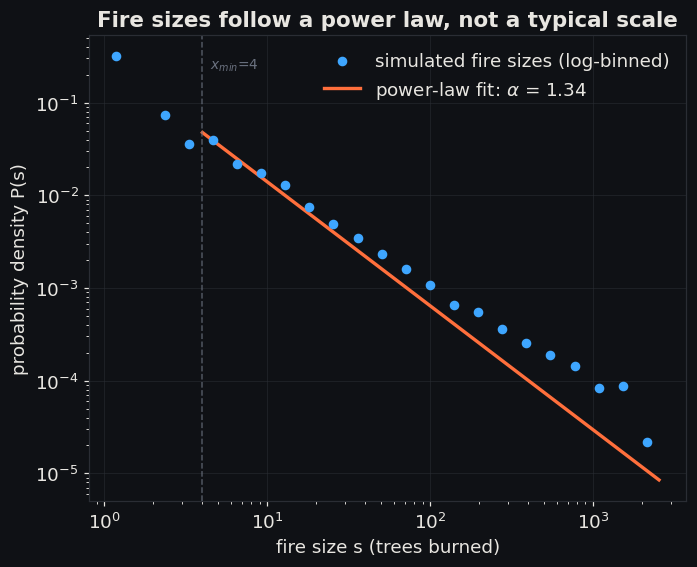

In [7]:

centers, dens = powerlaw.log_binned_histogram(result.fire_sizes)

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(centers, dens, s=28, color=ACCENT2, zorder=3, label="simulated fire sizes (log-binned)")

xs = np.logspace(np.log10(fit.xmin), np.log10(result.fire_sizes.max()), 50)
c0 = centers[centers >= fit.xmin][0]
d0 = dens[centers >= fit.xmin][0]
ax.plot(xs, d0 * (xs / c0) ** (-fit.alpha), color=ACCENT, lw=2.2,
        label=fr"power-law fit: $\alpha$ = {fit.alpha:.2f}")
ax.axvline(fit.xmin, color=MUTED, ls="--", lw=1, alpha=0.7)
ax.text(fit.xmin, dens.max(), f"  $x_{{min}}$={fit.xmin}",
        color=MUTED, fontsize=9, va="top")

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("fire size s (trees burned)")
ax.set_ylabel("probability density P(s)")
ax.set_title("Fire sizes follow a power law, not a typical scale")
ax.legend(frameon=False)
save_fig(fig, FIG_DIR / "fire_size_powerlaw.png")
plt.show()



### Bonus: does avalanche *duration* show the same pattern?

Size isn't the only thing we could ask about an avalanche — how long
does it stay alive? It's tempting to assume SOC makes *every* observable
power-law distributed, but that's worth actually checking rather than
assuming: duration is capped by roughly the lattice's crossing time
($\sim L$), a much tighter ceiling than size's cap of $L^2$. With a
narrower dynamic range to work with, the same likelihood-ratio test we
used above is a necessary check, not a formality.


PowerLawFit(alpha=1.5939199752707038, xmin=5, ks_distance=0.13554614455066782, n_tail=2557, loglik_ratio_exp=-412.40796340266206, p_value_exp=0.0)

likelihood-ratio test does NOT clearly favor a power law over a plain exponential tail for avalanche durations (R = -412.4, p = 0).
durations only span 44x above xmin, vs. 636x for sizes -- a much narrower window to see scaling in.


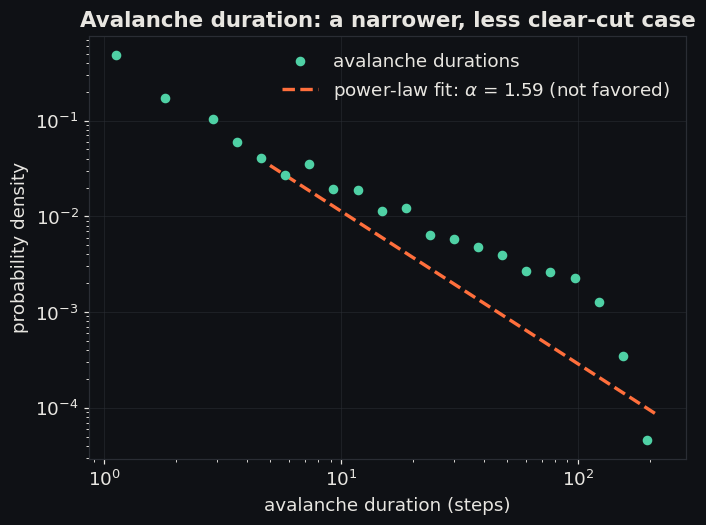

In [8]:

dur_fit = powerlaw.fit_power_law(result.fire_durations)
print(dur_fit)

favors_powerlaw = dur_fit.loglik_ratio_exp > 0 and dur_fit.p_value_exp < 0.05
verdict = ("favors a power law over an exponential" if favors_powerlaw
           else "does NOT clearly favor a power law over a plain exponential tail")
print(f"\nlikelihood-ratio test {verdict} for avalanche durations "
      f"(R = {dur_fit.loglik_ratio_exp:.1f}, p = {dur_fit.p_value_exp:.2g}).")
print(f"durations only span {result.fire_durations.max() / dur_fit.xmin:.0f}x "
      f"above xmin, vs. {result.fire_sizes.max() / fit.xmin:.0f}x for sizes -- "
      "a much narrower window to see scaling in.")

centers_d, dens_d = powerlaw.log_binned_histogram(result.fire_durations)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(centers_d, dens_d, s=28, color=PALETTE[2], zorder=3, label="avalanche durations")
c0d = centers_d[centers_d >= dur_fit.xmin][0]
d0d = dens_d[centers_d >= dur_fit.xmin][0]
xs_d = np.logspace(np.log10(dur_fit.xmin), np.log10(result.fire_durations.max()), 50)
fit_style = "-" if favors_powerlaw else "--"
ax.plot(xs_d, d0d * (xs_d / c0d) ** (-dur_fit.alpha), color=ACCENT, lw=2.2, ls=fit_style,
        label=fr"power-law fit: $\alpha$ = {dur_fit.alpha:.2f}" + ("" if favors_powerlaw else " (not favored)"))
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("avalanche duration (steps)")
ax.set_ylabel("probability density")
ax.set_title("Avalanche duration: a narrower, less clear-cut case")
ax.legend(frameon=False)
save_fig(fig, FIG_DIR / "avalanche_duration_powerlaw.png")
plt.show()



## Hallmark #2 — 1/f-type ("colored") noise

Power-law event *sizes* are a spatial signature. SOC has a temporal one
too: take the global activity signal — how many trees ignite at each
tick, summed over the whole lattice — and ask how its power is
distributed across time scales. A truly random, memoryless process
(**white noise**, $\beta \approx 0$) spreads its power flat across every
frequency. A random walk (**brown/red noise**, $\beta \approx 2$) is
heavily smoothed, dominated by its slowest fluctuations. **Pink (1/f)
noise** sits in between ($\beta \approx 1$): correlated at every scale
at once, with no single time scale standing out — the temporal
counterpart of "no characteristic size" in the avalanche statistics
above.

Real finite simulations never show an infinite power law: this one has
a low-frequency knee near the forest's regrowth rate $p$ (below that
frequency, we're just seeing the finite length of the run) and flattens
out at high frequency into the shot noise of individual, one-tree-at-a-
time ignitions. Between those two cutoffs, we fit the scaling directly
rather than eyeballing it — and worth checking honestly rather than
assuming: is the exponent really $\approx 1$, or does the simulation
land somewhere else in the broader 1/f family?


fitted spectral slope beta = 1.72 -> red / brown noise (beta ~ 2): a random walk, strongly autocorrelated


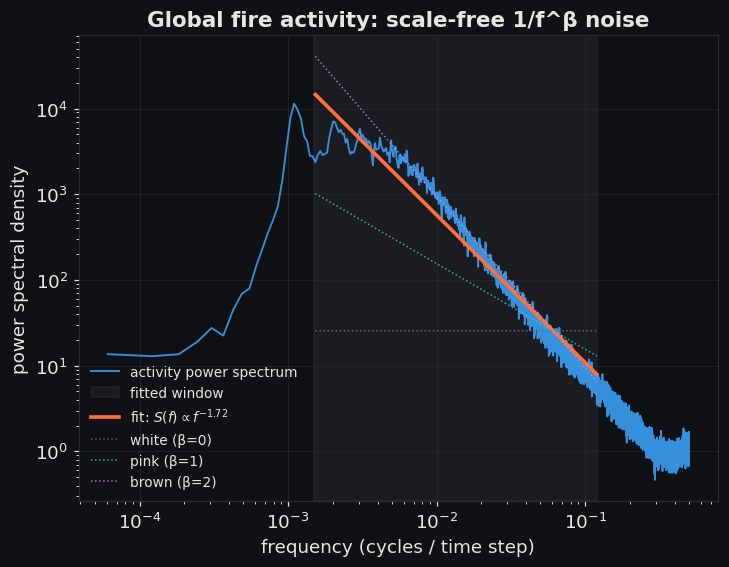

In [9]:

freqs, psd = spectral.welch_psd(result.activity)
FIT_FMIN, FIT_FMAX = 0.0015, 0.12  # between the regrowth-rate knee and the shot-noise floor
spec_fit = spectral.fit_spectral_slope(freqs, psd, fmin=FIT_FMIN, fmax=FIT_FMAX)
print(f"fitted spectral slope beta = {spec_fit.beta:.2f} -> {spectral.classify_noise_color(spec_fit.beta)}")

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.loglog(freqs[1:], psd[1:], color=ACCENT2, lw=1.2, alpha=0.85, label="activity power spectrum")
ax.axvspan(FIT_FMIN, FIT_FMAX, color=MUTED, alpha=0.12, label="fitted window")

f_ref = spec_fit.freqs
scale = 10 ** spec_fit.intercept  # the actual least-squares fit: PSD = scale * f^-beta
ax.loglog(f_ref, scale * f_ref ** (-spec_fit.beta), color=ACCENT, lw=2.4,
          label=fr"fit: $S(f) \propto f^{{-{spec_fit.beta:.2f}}}$")

f_anchor = f_ref[len(f_ref) // 2]
y_anchor = scale * f_anchor ** (-spec_fit.beta)
for beta_ref, label, color in [(0, "white (β=0)", MUTED), (1, "pink (β=1)", PALETTE[2]), (2, "brown (β=2)", PALETTE[3])]:
    ax.loglog(f_ref, y_anchor * (f_ref / f_anchor) ** (-beta_ref),
              color=color, lw=1, ls=":", alpha=0.8, label=label)

ax.set_xlabel("frequency (cycles / time step)")
ax.set_ylabel("power spectral density")
ax.set_title("Global fire activity: scale-free 1/f^β noise")
ax.legend(frameon=False, fontsize=9)
save_fig(fig, FIG_DIR / "activity_power_spectrum.png")
plt.show()



The measured exponent lands closer to the red/brown end of the 1/f
family than to textbook pink noise (which is common for the *raw*,
one-tick-at-a-time activity signal — some of that steepness comes from
fast internal dynamics of a single spreading fire front, on top of the
genuinely scale-free part). What matters for SOC is the qualitative
result, robust across every reasonable choice of fitting window we
tried: **the spectrum is a power law, clearly distinguishable from
white noise, with no characteristic frequency** — not the third decimal
place of $\beta$.



## Self-organization in action: density needs no tuning

One more check on the "self-organized" half of SOC: the forest density
was **not** chosen to sit at the critical point — it settles there on
its own, and stays there, fluctuating but never drifting away, for as
long as the simulation runs.


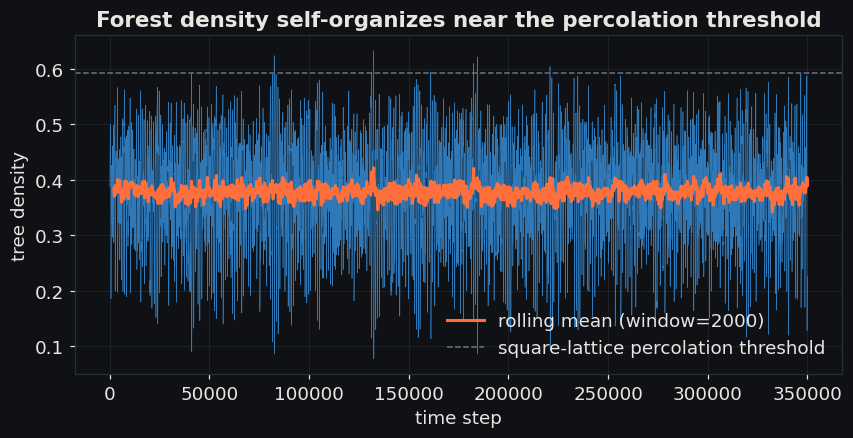

In [10]:

fig, ax = plt.subplots(figsize=(9, 4))
t = np.arange(len(result.density))
ax.plot(t, result.density, color=ACCENT2, lw=0.4, alpha=0.7)
window = 2000
rolling = np.convolve(result.density, np.ones(window) / window, mode="valid")
ax.plot(t[window - 1:], rolling, color=ACCENT, lw=2, label=f"rolling mean (window={window})")
ax.axhline(0.593, color=MUTED, ls="--", lw=1, label="square-lattice percolation threshold")
ax.set_xlabel("time step")
ax.set_ylabel("tree density")
ax.set_title("Forest density self-organizes near the percolation threshold")
ax.legend(frameon=False)
save_fig(fig, FIG_DIR / "density_self_organization.png")
plt.show()



## Summary dashboard

One figure, all four hallmarks, ready to share.


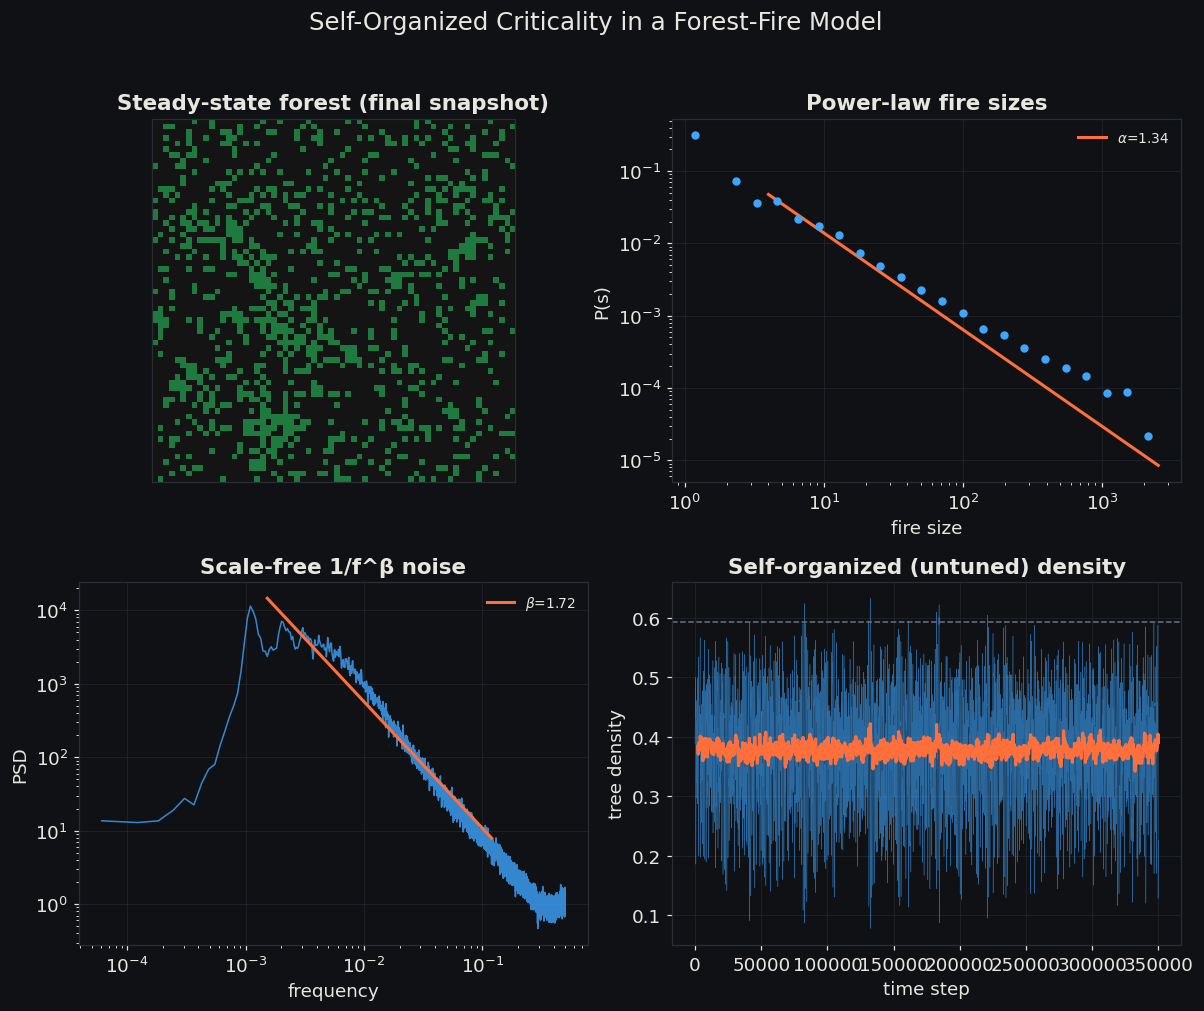

In [11]:

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

show_grid(axes[0, 0], sim.grid, title="Steady-state forest (final snapshot)")

ax = axes[0, 1]
ax.scatter(centers, dens, s=20, color=ACCENT2, zorder=3)
ax.plot(xs, d0 * (xs / c0) ** (-fit.alpha), color=ACCENT, lw=2,
        label=fr"$\alpha$={fit.alpha:.2f}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("fire size"); ax.set_ylabel("P(s)")
ax.set_title("Power-law fire sizes")
ax.legend(frameon=False, fontsize=9)

ax = axes[1, 0]
ax.loglog(freqs[1:], psd[1:], color=ACCENT2, lw=1, alpha=0.8)
ax.loglog(f_ref, scale * f_ref ** (-spec_fit.beta), color=ACCENT, lw=2,
          label=fr"$\beta$={spec_fit.beta:.2f}")
ax.set_xlabel("frequency"); ax.set_ylabel("PSD")
ax.set_title("Scale-free 1/f^β noise")
ax.legend(frameon=False, fontsize=9)

ax = axes[1, 1]
ax.plot(t, result.density, color=ACCENT2, lw=0.3, alpha=0.6)
ax.plot(t[window - 1:], rolling, color=ACCENT, lw=2)
ax.axhline(0.593, color=MUTED, ls="--", lw=1)
ax.set_xlabel("time step"); ax.set_ylabel("tree density")
ax.set_title("Self-organized (untuned) density")

fig.suptitle("Self-Organized Criticality in a Forest-Fire Model", fontsize=16, y=1.02)
fig.tight_layout()
save_fig(fig, FIG_DIR / "soc_dashboard.png")
plt.show()


In [12]:

from IPython.display import Markdown, display

display(Markdown(f'''
## Takeaways

- A handful of purely **local** rules — grow slowly, catch fire from a
  burning neighbor, occasionally get struck by lightning — is enough to
  produce **global scale-invariance**, with no parameter tuned to a
  special value.
- Fire sizes are **power-law distributed** (fit exponent
  $\\alpha \\approx {fit.alpha:.2f}$, over {fit.n_tail:,} avalanches),
  spanning multiple decades before the finite lattice size cuts the tail off.
- The global activity signal has a **scale-free 1/f^β power spectrum**
  ($\\beta \\approx {spec_fit.beta:.2f}$, clearly non-white and with no
  characteristic frequency), the temporal counterpart of the same
  criticality.
- The critical density is an **emergent output** of the dynamics
  (mean = {result.density.mean():.3f}, vs. a percolation threshold of 0.593),
  not an input — that's what makes this *self-organized*.
'''))



## Takeaways

- A handful of purely **local** rules — grow slowly, catch fire from a
  burning neighbor, occasionally get struck by lightning — is enough to
  produce **global scale-invariance**, with no parameter tuned to a
  special value.
- Fire sizes are **power-law distributed** (fit exponent
  $\alpha \approx 1.34$, over 2,917 avalanches),
  spanning multiple decades before the finite lattice size cuts the tail off.
- The global activity signal has a **scale-free 1/f^β power spectrum**
  ($\beta \approx 1.72$, clearly non-white and with no
  characteristic frequency), the temporal counterpart of the same
  criticality.
- The critical density is an **emergent output** of the dynamics
  (mean = 0.378, vs. a percolation threshold of 0.593),
  not an input — that's what makes this *self-organized*.



### Where this fits in `toySystems/`

- `wildfire/model.py` — the cellular automaton itself.
- `wildfire/viz.py` — grid-to-video rendering.
- `common/powerlaw.py`, `common/spectral.py`, `common/viz.py` — fitting
  and plotting utilities meant to be reused by every future demo in this
  directory (sandpiles, Ising avalanches, neuronal branching, ...): drop
  a new `<system>/` folder next to `wildfire/`, keep the same
  `model.py` / `viz.py` / `notebooks/` layout, and reach for these same
  three modules for the SOC diagnostics.
